# ДЗ 1
### Закирова Е. А.


## загрузка данных

загрузка данных требует интернета!

In [ ]:
# %pip install pandas numpy matplotlib statsmodels ucimlrepo

In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [115]:
from ucimlrepo import fetch_ucirepo 
  
online_retail = fetch_ucirepo(id=352) 
  
X = online_retail.data.features 
y = online_retail.data.targets 
  
#print(online_retail.metadata) 
  
df = online_retail.data.original
df.head(20)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/2010 8:34,1.69,13047.0,United Kingdom


In [116]:
df.shape

(541909, 8)

In [117]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [118]:
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [119]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


## продажи

выбрала товар с StockCode = 21755, называется LOVE BUILDING BLOCK WORD

StockCode нужен для отбора товара, Description - для проверки названия,
InvoiceDate - для даты, Quantity - для количества проданных штук

InvoiceNo и UnitPrice использую, чтобы отделить отмены и бесплатные операции

продажи по всем странам вместе

In [120]:
product = df[df["StockCode"].astype(str) == "21755"].copy()
print(f'{len(product)} записей товара 21755')
product.isna().sum()

656 записей товара 21755


InvoiceNo       0
StockCode       0
Description     0
Quantity        0
InvoiceDate     0
UnitPrice       0
CustomerID     74
Country         0
dtype: int64

In [121]:
product["Description"].value_counts(dropna=False)

Description
LOVE BUILDING BLOCK WORD    656
Name: count, dtype: int64

в CustomerID 74 пропуска, но номер покупателя для суммы продаж не нужен, поэтому все равно

в дате и количестве пропусков у выбранного товара нет

исключим отмененные операции, неположительное количество и неположительную цену

возвраты не вычитаю, тк считаю только положительные платные продажи

In [122]:
def prepare_sales(product):
    cancelled = product["InvoiceNo"].astype(str).str.startswith("C")

    sales = product[
        (~cancelled)
        & (product["Quantity"] > 0)
        & (product["UnitPrice"] > 0)
    ].copy()

    sales["InvoiceDate"] = pd.to_datetime(
        sales["InvoiceDate"],
        format="%m/%d/%Y %H:%M"
    )
    sales = sales.sort_values("InvoiceDate")
    return sales.set_index("InvoiceDate")

In [123]:
sales = prepare_sales(product)
print(f"{len(sales)} стало записей продаж")
print("исключено записей:", len(product) - len(sales))
print("начало:", sales.index.min())
print("конец:", sales.index.max())

654 стало записей продаж
исключено записей: 2
начало: 2010-12-01 08:34:00
конец: 2011-12-09 12:00:00


In [124]:
sales.head()

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
InvoiceDate,,,,,,,
2010-12-01 08:34:00,536367,21755,LOVE BUILDING BLOCK WORD,3,5.95,13047.0,United Kingdom
2010-12-01 09:59:00,536388,21755,LOVE BUILDING BLOCK WORD,3,5.95,16250.0,United Kingdom
2010-12-01 11:41:00,536408,21755,LOVE BUILDING BLOCK WORD,3,5.95,14307.0,United Kingdom
2010-12-01 12:35:00,536500,21755,LOVE BUILDING BLOCK WORD,6,5.95,17377.0,United Kingdom
2010-12-01 17:06:00,536592,21755,LOVE BUILDING BLOCK WORD,1,11.87,NaN,United Kingdom


## агрегация

одна строка пока означает операцию с товаром, а надо посчитать за каждый день, неделю и месяц

W-SUN - неделя с понедельника по воскресенье, дата в результате -
воскресенье

MS - календарный месяц с 1 числа

min_count=1 пока оставляет NaN, если за весь период нет записей

In [125]:
def aggregate_sales(sales, frequency):
    return sales["Quantity"].resample(frequency).sum(min_count=1)

daily_sales = aggregate_sales(sales, "D")
daily_sales.head()

InvoiceDate
2010-12-01    16.0
2010-12-02     7.0
2010-12-03     4.0
2010-12-04     NaN
2010-12-05    10.0
Freq: D, Name: Quantity, dtype: float64

In [126]:
weekly_sales = aggregate_sales(sales, "W-SUN")
weekly_sales.head()

InvoiceDate
2010-12-05    37.0
2010-12-12    64.0
2010-12-19    29.0
2010-12-26    12.0
2011-01-02     NaN
Freq: W-SUN, Name: Quantity, dtype: float64

In [127]:
monthly_sales = aggregate_sales(sales, "MS")
monthly_sales

InvoiceDate
2010-12-01    142
2011-01-01    333
2011-02-01    201
2011-03-01    124
2011-04-01    140
2011-05-01    203
2011-06-01    189
2011-07-01     78
2011-08-01    124
2011-09-01    174
2011-10-01    112
2011-11-01    180
2011-12-01     34
Freq: MS, Name: Quantity, dtype: int64

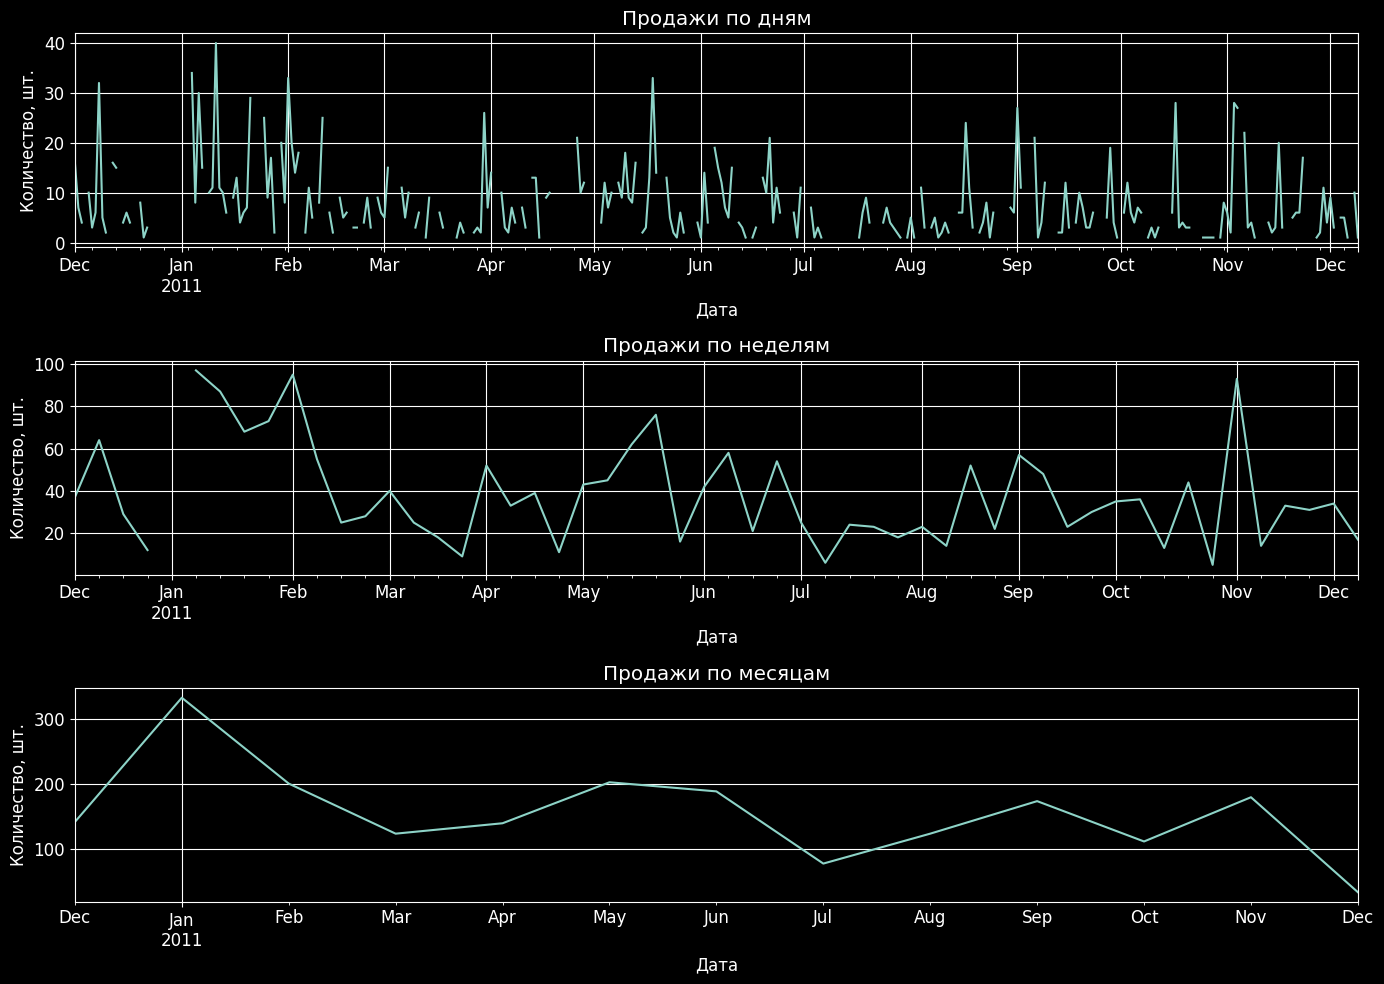

In [128]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

daily_sales.plot(ax=axes[0], title="Продажи по дням")
weekly_sales.plot(ax=axes[1], title="Продажи по неделям")
monthly_sales.plot(ax=axes[2], title="Продажи по месяцам")

for ax in axes:
    ax.set_xlabel("Дата")
    ax.set_ylabel("Количество, шт.")
    ax.grid(True)

plt.tight_layout()
plt.show()

дневной ряд оставляет больше деталей, недельный сглаживает отдельные скачки,
месячный показывает общие изменения, но точек в нем мало

период - с 1 декабря 2010 по 9 декабря 2011

первая и последняя недели неполные, декабрь 2011 тоже неполный


## пропуски и качество данных

In [129]:
daily_sales.isna().sum()

np.int64(113)

In [130]:
def inspect_missing_days(series, data):
    all_dates = pd.to_datetime(
        data["InvoiceDate"],
        format="%m/%d/%Y %H:%M"
    ).dt.normalize()

    missing_dates = series.index[series.isna()]
    missing_info = pd.DataFrame(index=missing_dates)
    missing_info.index.name = "Дата"
    missing_info["Есть операции в датасете"] = missing_dates.isin(all_dates)
    weekdays = ["пн", "вт", "ср", "чт", "пт", "сб", "вс"]
    missing_info["День недели"] = [
        weekdays[day] for day in missing_dates.dayofweek
    ]
    return missing_info

missing_info = inspect_missing_days(daily_sales, df)
unknown_dates = missing_info.index[
    ~missing_info["Есть операции в датасете"]
]

print("всего дней в ряду:", len(daily_sales))
print("дней без записей товара:", len(missing_info))
print("из них с операциями в датасете:",
      missing_info["Есть операции в датасете"].sum())
print("из них вообще без операций:", len(unknown_dates))

with pd.option_context("display.max_rows", None):
    display(missing_info)

print("дни недели без каких-либо операций:")
display(missing_info.loc[unknown_dates, "День недели"].value_counts())

всего дней в ряду: 374
дней без записей товара: 113
из них с операциями в датасете: 44
из них вообще без операций: 69


,Есть операции в датасете,День недели
Дата,,
2010-12-04,False,сб
2010-12-11,False,сб
2010-12-14,True,вт
2010-12-18,False,сб
2010-12-19,True,вс
2010-12-23,True,чт
2010-12-24,False,пт
2010-12-25,False,сб
2010-12-26,False,вс


дни недели без каких-либо операций:


День недели
сб    53
пн     6
пт     4
вс     3
вт     1
ср     1
чт     1
Name: count, dtype: int64

получилось 113 дней без записей товара: в 44 есть операции в датасете,
а в 69 нет никаких операций

из этих 69 дней 53 - субботы.
это похоже на особенности работы магазина

отсутствие записей занулила

для 69 неопределенных дней дополнительно попробовала интерполяцию между соседними
значениями

### потенциальные выбросы

использую IQR: значения ниже Q1 - 1,5 * IQR и выше Q3 + 1,5 * IQR

границы IQR: -7.5 20.5
потенциальных выбросов: 19


,"Количество, шт."
InvoiceDate,
2010-12-08,32.0
2011-01-04,34.0
2011-01-06,30.0
2011-01-11,40.0
2011-01-21,29.0
2011-01-25,25.0
2011-02-01,33.0
2011-02-11,25.0
2011-03-30,26.0


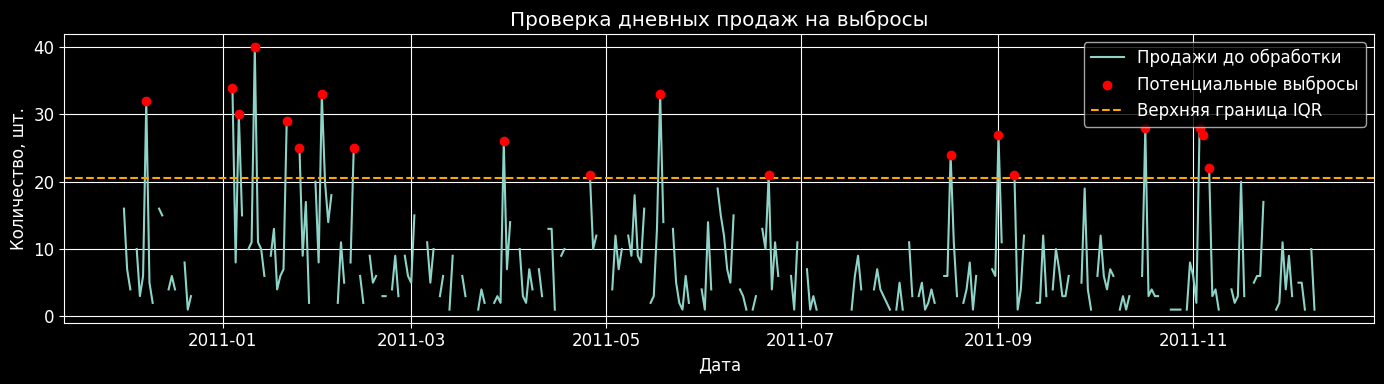

In [131]:
def find_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = series[(series < lower) | (series > upper)]
    return outliers, lower, upper

outliers, lower, upper = find_outliers(daily_sales)
print("границы IQR:", lower, upper)
print("потенциальных выбросов:", len(outliers))
display(outliers.to_frame("Количество, шт."))

plt.figure(figsize=(14, 4))
plt.plot(daily_sales.index, daily_sales, label="Продажи до обработки")
plt.scatter(
    outliers.index, outliers, color="red",
    label="Потенциальные выбросы", zorder=3
)
plt.axhline(upper, color="orange", linestyle="--", label="Верхняя граница IQR")
plt.title("Проверка дневных продаж на выбросы")
plt.xlabel("Дата")
plt.ylabel("Количество, шт.")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

найдено 19 дней с продажами выше 20,5 штуки

максимум - 40, ну и большой объем может быть настоящим заказом, а не ошибкой

подтверждения ошибки нет, поэтому выбросы не удаляю и не обрезаю

## описательные статистики

In [132]:
def describe_sales(series):
    statistics = series.describe()
    statistics["Дней без значения"] = series.isna().sum()
    statistics["Асимметрия"] = series.skew()
    return statistics

describe_sales(daily_sales) #ну это база

count                261.000000
mean                   7.793103
std                    7.283498
min                    1.000000
25%                    3.000000
50%                    6.000000
75%                   10.000000
max                   40.000000
Дней без значения    113.000000
Асимметрия             1.776236
Name: Quantity, dtype: float64

In [133]:
daily_sales.median() #медиана

np.float64(6.0)

In [134]:
daily_sales.skew() #асимметрия

np.float64(1.7762362366657174)

среди 261 дня с записями средние продажи - 7,79 штуки, медиана - 6,
стандартное отклонение - 7,28

среднее выше медианы:
редкие большие значения тянут его вверх

асимметрия 1,78 тоже указывает
на вытянутость в сторону больших продаж

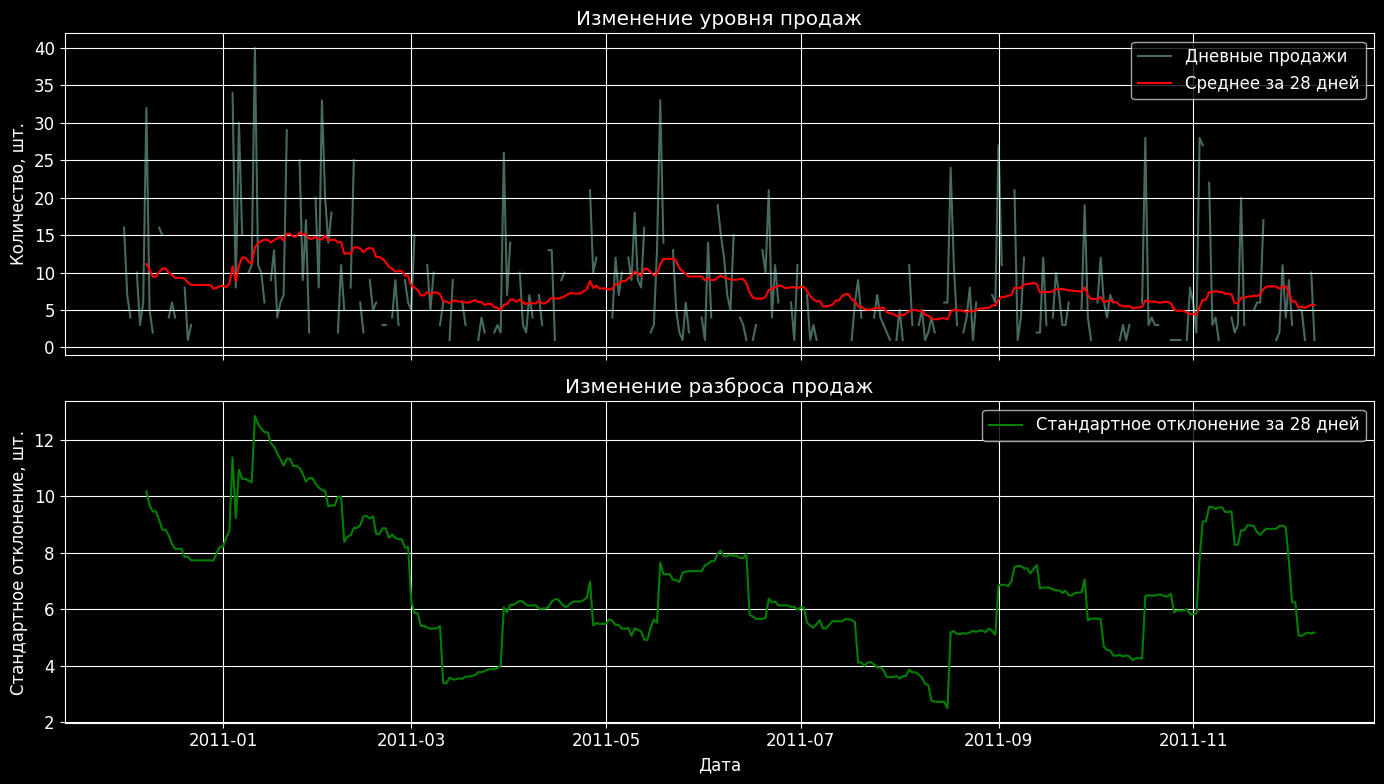

In [135]:
def rolling_statistics(series, window=28, min_periods=7):
    rolling = series.rolling(window, min_periods=min_periods)
    return rolling.mean(), rolling.std()

rolling_mean, rolling_std = rolling_statistics(daily_sales)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(
    daily_sales.index, daily_sales,
    label="Дневные продажи", alpha=0.5
)
axes[0].plot(
    rolling_mean.index, rolling_mean,
    label="Среднее за 28 дней", color="red"
)
axes[0].set_title("Изменение уровня продаж")
axes[0].set_ylabel("Количество, шт.")
axes[0].legend()

axes[1].plot(
    rolling_std.index, rolling_std,
    label="Стандартное отклонение за 28 дней", color="green"
)
axes[1].set_title("Изменение разброса продаж")
axes[1].set_xlabel("Дата")
axes[1].set_ylabel("Стандартное отклонение, шт.")
axes[1].legend()

for ax in axes:
    ax.grid(True)

plt.tight_layout()
plt.show()

скользящие характеристики рассчитаны в окне 28 календарных дней при наличии
не менее 7 наблюдений

пропуски не участвуют в среднем и стандартном отклонении,
поэтому число известных дней в каждом окне может отличаться

в январе уровень и разброс выше, чем летом. потом среднее снижается,
но отдельные всплески остаются

постоянного роста продаж не видно

разброс тоже меняется: в начале года колебания сильнее, летом слабее

## stl

надо разделить ряд на тренд, сезонную часть и остаток, поэтому stl

robust=True уменьшает влияние отдельных всплесков на оценку компонентов,
но не удаляет их из данных

проверю предполагаемую сезонность в 7 дней: покупки могут зависеть от дня недели

In [136]:
from statsmodels.tsa.seasonal import STL

def prepare_daily_variants(series, unknown_dates):
    zero_sales = series.fillna(0)
    alternative = zero_sales.copy()
    alternative.loc[unknown_dates] = np.nan
    alternative = alternative.interpolate(
        method="time", limit_area="inside"
    )
    return zero_sales, alternative

def decompose_sales(series):
    if series.isna().any():
        raise ValueError("перед STL нужно разобраться с пропусками")
    result = STL(series, period=7, robust=True).fit()
    return result

sales_for_stl, alternative_sales = prepare_daily_variants(
    daily_sales, unknown_dates
)
result = decompose_sales(sales_for_stl)

,Только дни с записями,Отсутствие записей принято за 0
count,261.000000,374.000000
mean,7.793103,5.438503
std,7.283498,7.058181
min,1.000000,0.000000
25%,3.000000,0.000000
50%,6.000000,3.000000
75%,10.000000,8.000000
max,40.000000,40.000000
Дней без значения,113.000000,0.000000
Асимметрия,1.776236,1.990992


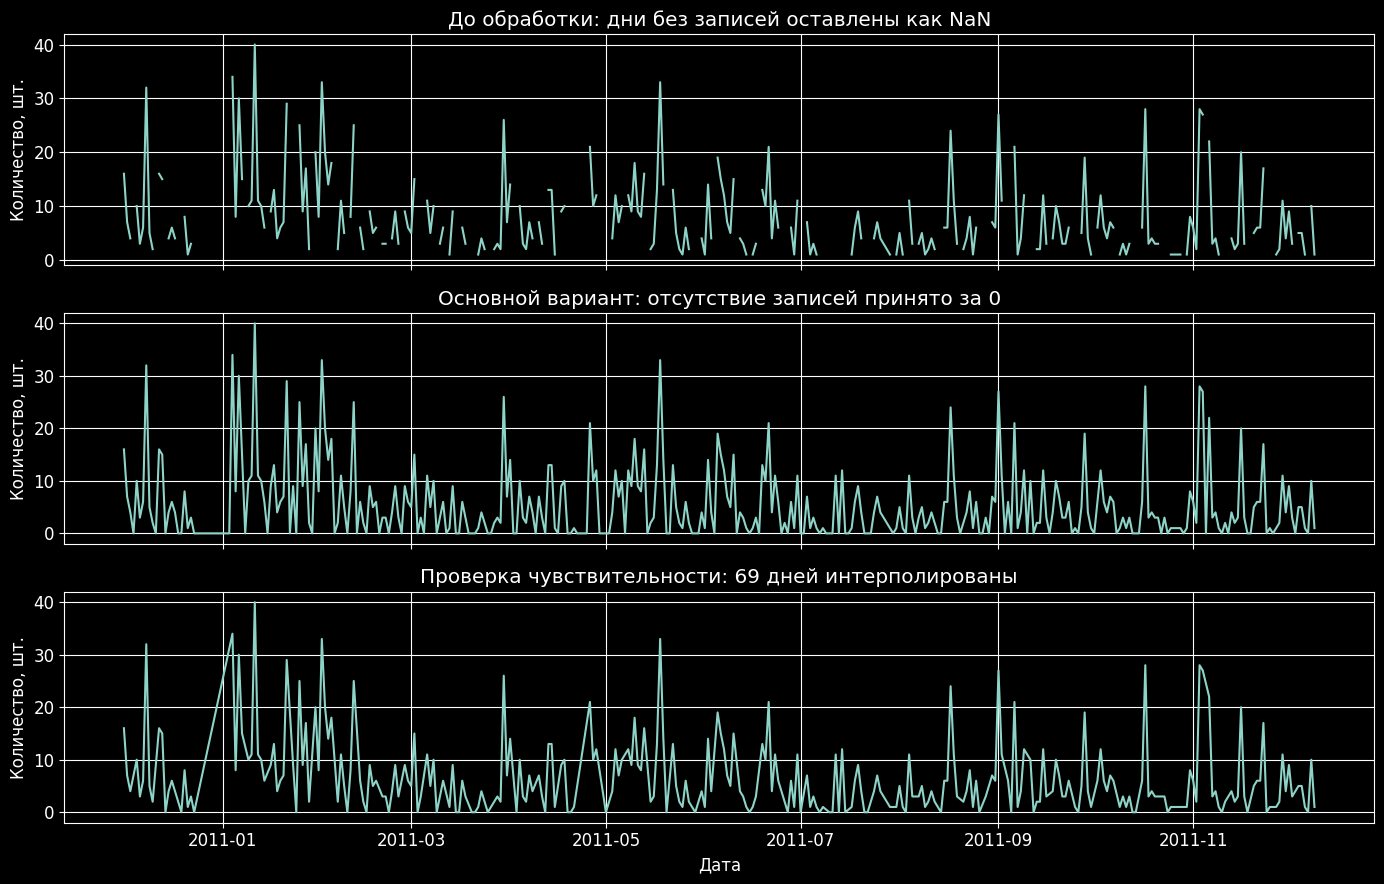

In [137]:
display(pd.DataFrame({
    "Только дни с записями": describe_sales(daily_sales),
    "Отсутствие записей принято за 0": describe_sales(sales_for_stl)
}))

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
variants = [daily_sales, sales_for_stl, alternative_sales]
names = [
    "До обработки: дни без записей оставлены как NaN",
    "Основной вариант: отсутствие записей принято за 0",
    "Проверка чувствительности: 69 дней интерполированы"
]

for ax, series, name in zip(axes, variants, names):
    ax.plot(series.index, series)
    ax.set_title(name)
    ax.set_ylabel("Количество, шт.")
    ax.grid(True)

axes[-1].set_xlabel("Дата")
plt.tight_layout()
plt.show()

после добавления нулевых дней среднее стало 5,44, медиана — 3.
это уже характеристики всех 374 календарных дней

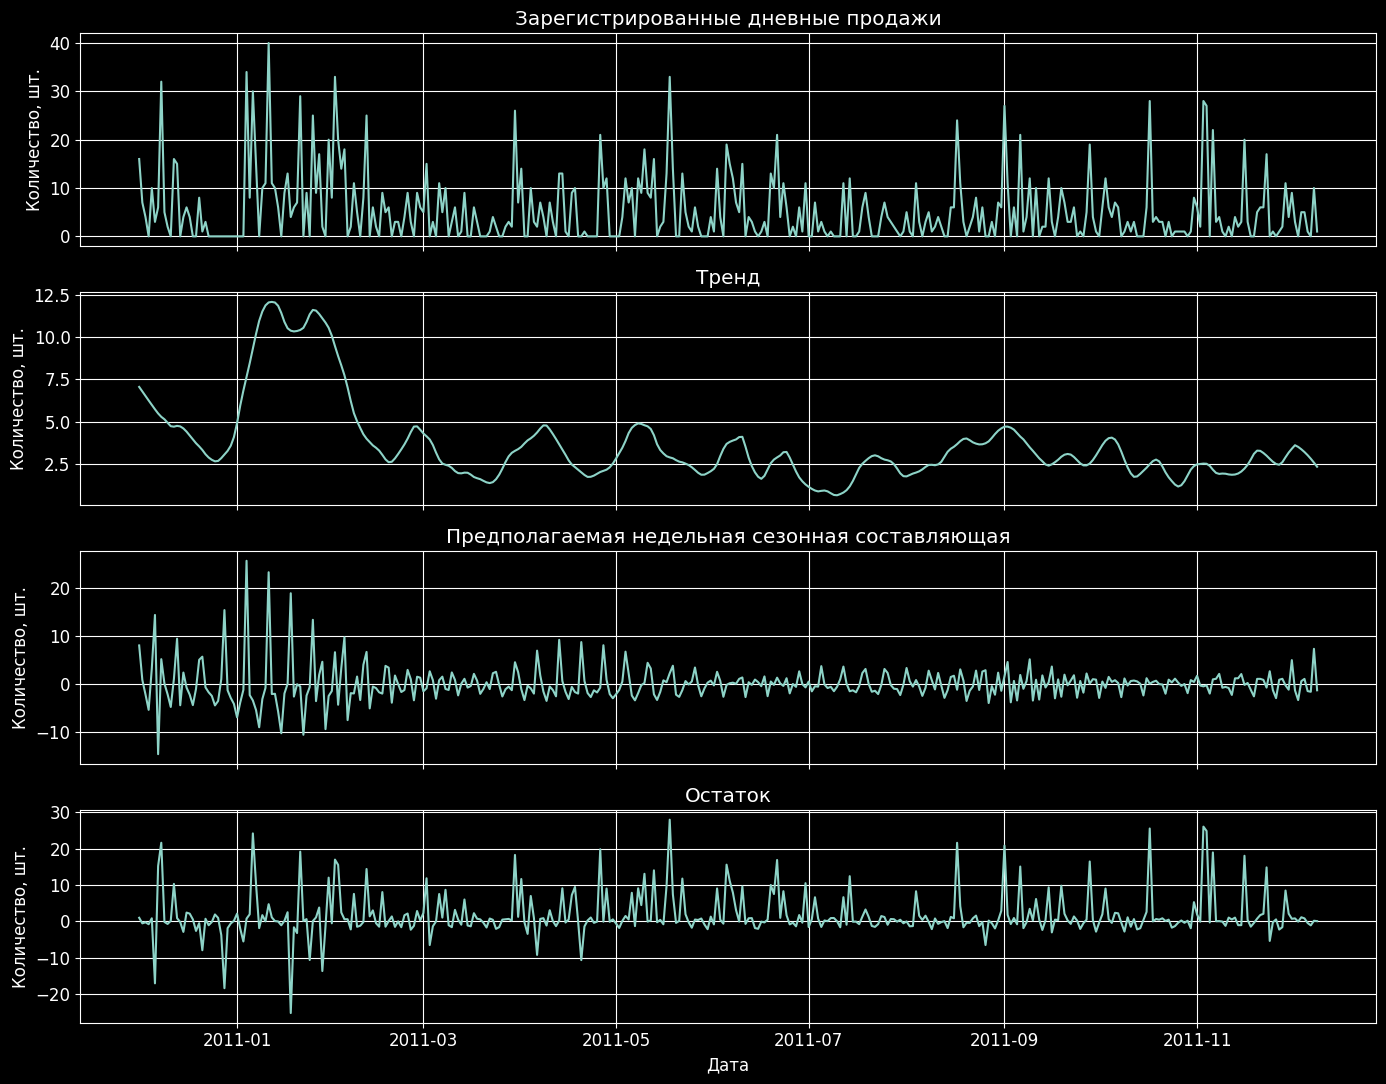

In [138]:
fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)

components = [
    sales_for_stl,
    result.trend,
    result.seasonal,
    result.resid
]

titles = [
    "Зарегистрированные дневные продажи",
    "Тренд",
    "Предполагаемая недельная сезонная составляющая",
    "Остаток"
]

for ax, component, title in zip(axes, components, titles):
    ax.plot(component.index, component)
    ax.set_title(title)
    ax.set_ylabel("Количество, шт.")
    ax.grid(True)

axes[-1].set_xlabel("Дата")

plt.tight_layout()
plt.show()

тренд показывает высокий уровень в январе, затем снижение и более низкий
уровень летом. в остатке остаются большие положительные и отрицательные
отклонения: тренд и недельная часть не объясняют все скачки.
считать остаток белым шумом только по этому графику нельзя.

In [139]:
def seasonal_strength(result):
    variance = (result.seasonal + result.resid).var()

    if variance == 0:
        raise ValueError("сила сезонности не определена при нулевом разбросе")

    strength = 1 - result.resid.var() / variance
    return max(0, strength)

strength = seasonal_strength(result)

print("Сила сезонности:", round(strength, 3))

Сила сезонности: 0.172


значение ближе к 0 означает слабую сезонную компоненту (в 7 дней).
это описательная оценка, а не вероятность наличия сезонности.
дополнительно посмотрю связь значений через неделю после удаления тренда.

In [140]:
without_trend = sales_for_stl - result.trend

print("Корреляция с лагом 7 дней:", round(without_trend.autocorr(lag=7), 3))

Корреляция с лагом 7 дней: 0.078


In [141]:
alternative_result = decompose_sales(alternative_sales)

seasonality_comparison = pd.DataFrame({
    "Сила сезонности": [
        seasonal_strength(result),
        seasonal_strength(alternative_result)
    ],
    "Корреляция с лагом 7": [
        without_trend.autocorr(lag=7),
        (alternative_sales - alternative_result.trend).autocorr(lag=7)
    ]
}, index=["Нулевые дни", "Интерполяция 69 дней"])

display(seasonality_comparison.round(3))

,Сила сезонности,Корреляция с лагом 7
Нулевые дни,0.172,0.078
Интерполяция 69 дней,0.082,-0.089


в основном варианте сила сезонности: 0,172, корреляция через 7 дней: 0,078.
при интерполяции сила сезонности: 0,082, корреляция: -0,089.
выраженной недельной сезонности нет в обоих вариантах

## стационарность

проверю ряд до удаления тренда и сезонности. исходным здесь называю дневной ряд
с принятым заполнением отсутствующих записей нулями.

использую уровень значимости 0,05:

- ADF: нулевая гипотеза - есть единичный корень. p-value < 0,05 позволяет ее отвергнуть;
- KPSS: нулевая гипотеза - стационарность относительно постоянного уровня.
  p-value < 0,05 позволяет ее отвергнуть.

если ADF < 0,05, а KPSS >= 0,05, тесты согласуются со стационарностью,
но не доказывают ее окончательно

лаги нужны тестам для учета зависимости между наблюдениями во времени

In [142]:
from statsmodels.tsa.stattools import adfuller, kpss

def check_stationarity(series, kpss_lags="auto"):
    if series.isna().any():
        raise ValueError("для тестов нужен регулярный ряд без пропусков")

    adf_result = adfuller(series, regression="c", autolag="AIC")
    kpss_result = kpss(series, regression="c", nlags=kpss_lags)

    return pd.Series({
        "Количество наблюдений": len(series),
        "Статистика ADF": adf_result[0],
        "p-value ADF": adf_result[1],
        "Лаги ADF": adf_result[2],
        "Статистика KPSS": kpss_result[0],
        "p-value KPSS": kpss_result[1],
        "Лаги KPSS": kpss_result[2]
    })

In [143]:
original_series = sales_for_stl.copy()

original_tests = check_stationarity(original_series)

original_tests.to_frame("Исходный ряд")

C:\Users\awegis\AppData\Local\Temp\ipykernel_7180\3863044981.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series, regression="c", autolag="AIC")
C:\Users\awegis\AppData\Local\Temp\ipykernel_7180\3863044981.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_result = kpss(series, regression="c", nlags

,Исходный ряд
Количество наблюдений,3.740000e+02
Статистика ADF,-1.129851e+01
p-value ADF,1.325233e-20
Лаги ADF,1.000000e+00
Статистика KPSS,4.895479e-01
p-value KPSS,4.402075e-02
Лаги KPSS,5.000000e+00


ADF: p-value 1,33 * 10^(-20) - гипотеза единичного корня отвергается

KPSS: p-value 0,044 - стационарность относительно постоянного уровня отвергается на уровне 0,05

результаты разошлись: ADF отвергает наличие единичного корня,
но KPSS отвергает стационарность.
дополнительно проверю первые разности: продажи сегодня минус продажи вчера

In [144]:
diff_sales = original_series.diff().iloc[1:]

diff_tests = check_stationarity(diff_sales)
diff_tests.to_frame("Первые разности")

C:\Users\awegis\AppData\Local\Temp\ipykernel_7180\3863044981.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series, regression="c", autolag="AIC")
C:\Users\awegis\AppData\Local\Temp\ipykernel_7180\3863044981.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_result = kpss(series, regression="c", nlags

,Первые разности
Количество наблюдений,3.730000e+02
Статистика ADF,-9.562016e+00
p-value ADF,2.411773e-16
Лаги ADF,1.200000e+01
Статистика KPSS,5.000000e-01
p-value KPSS,4.166667e-02
Лаги KPSS,3.720000e+02


In [145]:
display(pd.DataFrame({
    "Исходный ряд": original_tests,
    "Первые разности": diff_tests
}))

,Исходный ряд,Первые разности
Количество наблюдений,3.740000e+02,3.730000e+02
Статистика ADF,-1.129851e+01,-9.562016e+00
p-value ADF,1.325233e-20,2.411773e-16
Лаги ADF,1.000000e+00,1.200000e+01
Статистика KPSS,4.895479e-01,5.000000e-01
p-value KPSS,4.402075e-02,4.166667e-02
Лаги KPSS,5.000000e+00,3.720000e+02


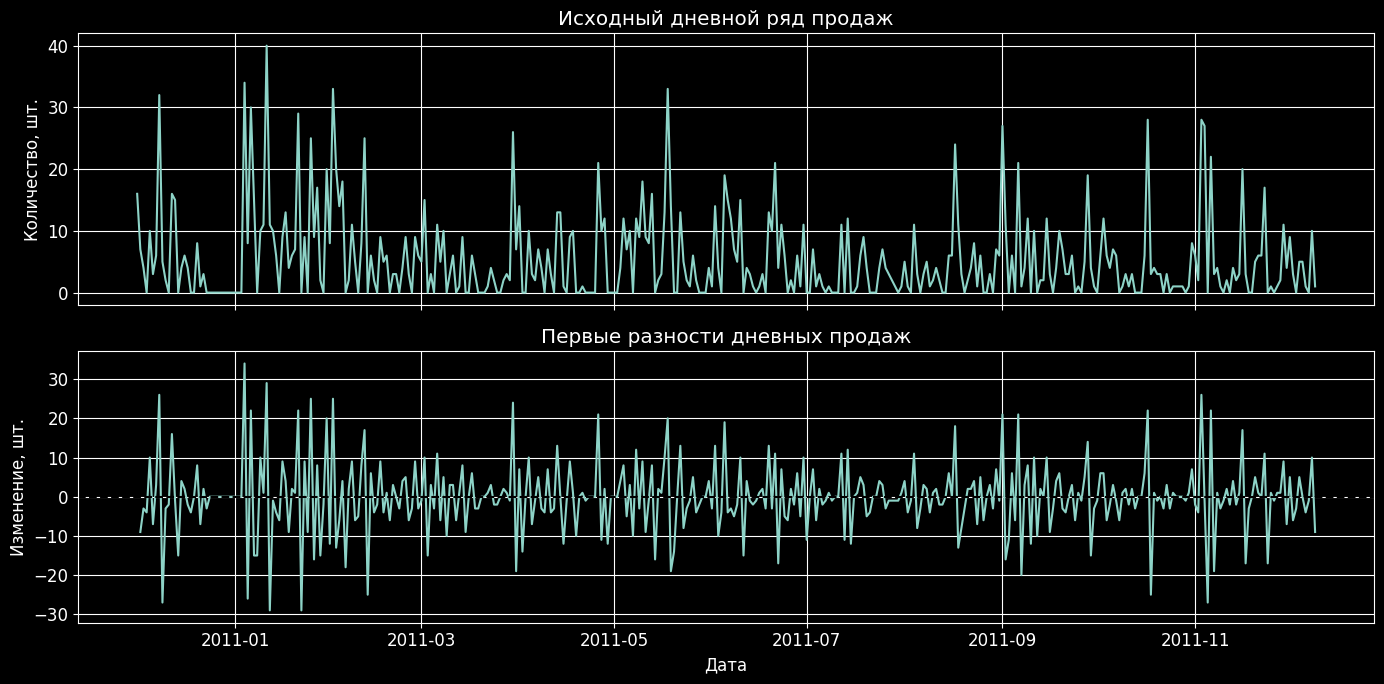

In [146]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(original_series.index, original_series)
axes[0].set_title("Исходный дневной ряд продаж")
axes[0].set_ylabel("Количество, шт.")

axes[1].plot(diff_sales.index, diff_sales)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_title("Первые разности дневных продаж")
axes[1].set_ylabel("Изменение, шт.")
axes[1].set_xlabel("Дата")

for ax in axes:
    ax.grid(True)

plt.tight_layout()
plt.show()

после первых разностей тесты опять расходятся, причем auto выбрал
372 лага KPSS на 373 наблюдения

для проверки использую еще стандартное правило nlags="legacy".
оно выбирает число лагов по длине ряда: int(12 * (n / 100) ** 0,25).
здесь получается 17 лагов

In [147]:
original_legacy = check_stationarity(original_series, kpss_lags="legacy")
diff_legacy = check_stationarity(diff_sales, kpss_lags="legacy")
alternative_tests = check_stationarity(
    alternative_sales, kpss_lags="legacy"
)
alternative_diff = alternative_sales.diff().iloc[1:]
alternative_diff_tests = check_stationarity(
    alternative_diff, kpss_lags="legacy"
)

stationarity_comparison = pd.DataFrame({
    "Нули: исходный": original_legacy,
    "Нули: разности": diff_legacy,
    "Интерполяция: исходный": alternative_tests,
    "Интерполяция: разности": alternative_diff_tests
})
display(stationarity_comparison)

C:\Users\awegis\AppData\Local\Temp\ipykernel_7180\3863044981.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series, regression="c", autolag="AIC")
C:\Users\awegis\AppData\Local\Temp\ipykernel_7180\3863044981.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_result = kpss(series, regression="c", nlags

,Нули: исходный,Нули: разности,Интерполяция: исходный,Интерполяция: разности
Количество наблюдений,3.740000e+02,3.730000e+02,3.740000e+02,3.730000e+02
Статистика ADF,-1.129851e+01,-9.562016e+00,-5.926914e+00,-1.059260e+01
p-value ADF,1.325233e-20,2.411773e-16,2.431467e-07,6.469831e-19
Лаги ADF,1.000000e+00,1.200000e+01,5.000000e+00,7.000000e+00
Статистика KPSS,3.766942e-01,3.153155e-02,6.753781e-01,2.903125e-02
p-value KPSS,8.720076e-02,1.000000e-01,1.578381e-02,1.000000e-01
Лаги KPSS,1.700000e+01,1.700000e+01,1.700000e+01,1.700000e+01


при legacy у исходного ряда с нулями KPSS дает p-value около 0,087,
а у исходного ряда с интерполяцией - около 0,016

вывод об исходном ряде зависит и от заполнения дней, и от числа лагов

после первых разностей при legacy ADF дает p-value < 0,05,
а KPSS — p-value > 0,1 в обоих вариантах заполнения

## итоги

- для товара 21755 осталось 654 записи положительных платных продаж.
  построила дневной, недельный и месячный ряды;
- пропуски CustomerID не удаляла: они не мешают считать продажи товара;
- в 113 днях нет записей товара, в 69 из них нет операций вообще.
  нули использовала как допущение для зарегистрированных продаж,
  отдельно проверила интерполяцию этих 69 дней;
- нашла 19 потенциальных выбросов, но оставила их;
- среднее и разброс меняются, особенно выделяется начало 2011 года.
  устойчивого роста нет, выраженной недельной сезонности тоже не нашла;
- вывод о стационарности исходного ряда зависит от обработки и лагов KPSS.
  первые разности при стандартном правиле legacy согласуются со стационарностью
  в обоих вариантах заполнения, при auto тесты расходятся
